# ICON data
load, calc input variables, resample => using extracted functions

In [1]:
# import intake
# import healpy as hp

import numpy as np
import xarray as xr


import warnings
warnings.filterwarnings("ignore", category=FutureWarning)


# ALTERNATIVE VERSION B WITH FUNCTION
import sys
sys.path.append("../tools/")
import handle_ICON_data as ic


In [2]:
# data selection
zoom = 9
date = "2023-06-06-1800"
vlist = ["pr", "rlut", "tas", "qsvi","clivi","qgvi","crs"]

# load data
dataset = ic.open_ngc4008(zoom = zoom) 

# select timestamp and variables
dataset = ic.select_time(dataset, date)
dataset = ic.select_vars(dataset, vlist)

# calculate input variables 
dataset = ic.add_input_vars(dataset)
dataset


# resample to Imerg grid
ds = {}
ds["tas"]= ic.resample_to_lon_lat(dataset,  "tas", zoom = zoom,to_imerg = True)
ds["tb"] = ic.resample_to_lon_lat(dataset, "tb_11", zoom = zoom, to_imerg = True)
ds["precip"] = ic.resample_to_lon_lat(dataset ,"rain_tot_rate", zoom = zoom ,to_imerg = True)
ds["iwp"] = ic.resample_to_lon_lat(dataset, "iwp", zoom = zoom,to_imerg = True)


sh: getfattr: command not found
sh: getfattr: command not found
sh: getfattr: command not found
sh: getfattr: command not found


# (Plot resampled data)

In [3]:
ds["iwp"].time

<xarray.DataArray 'time' ()> Size: 8B
array('2023-06-06T18:00:00.000000000', dtype='datetime64[ns]')
Coordinates:
    time     datetime64[ns] 8B 2023-06-06T18:00:00
Attributes:
    axis:     T

/work/bb1376/user/leonie/conda/envs/MA_numpy23/lib/python3.11/site-packages/pyproj/network.py:59: UserWarning: pyproj unable to set PROJ database path.
  _set_context_ca_bundle_path(ca_bundle_path)


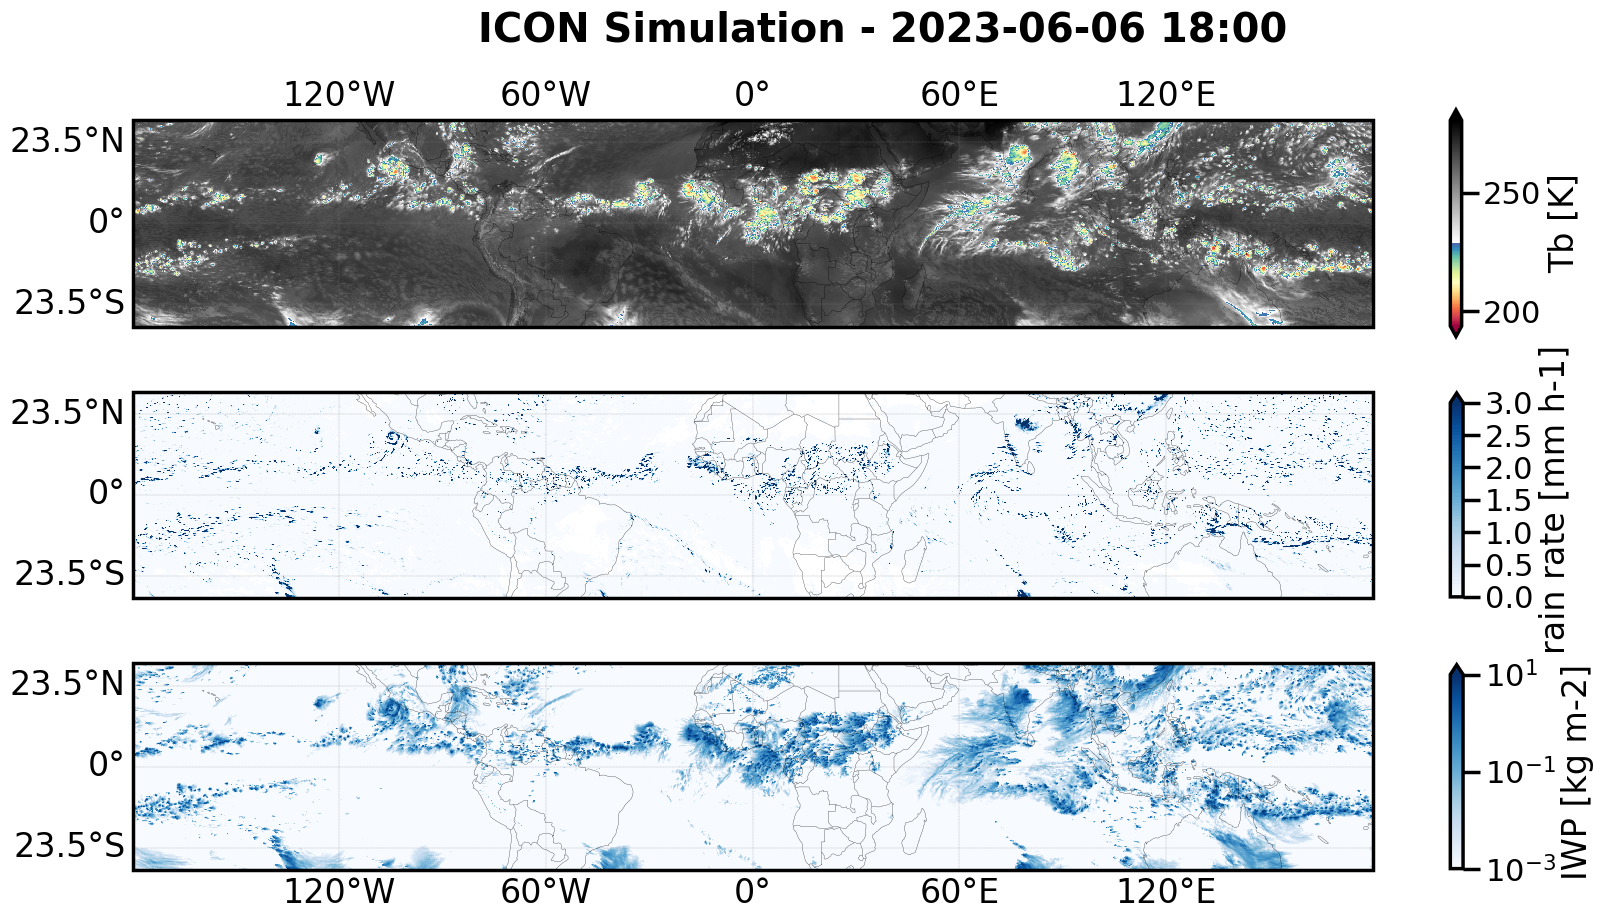

In [4]:
import plots_mapping  

date_label = plots_mapping.title_time_format(ds["iwp"])

fig = plots_mapping.summarized_plot(tb = ds["tb"],precip =ds["precip"] ,iwp= ds["iwp"],title= f"ICON Simulation - {date_label}")        

In [5]:
import os
output_directory = "../output/plots"
if not os.path.exists(os.path.join(output_directory)):
    os.makedirs(os.path.join(output_directory,), exist_ok=True)
    
fig.savefig(os.path.join(output_directory,f"joined_ICON_{date}.pdf"))

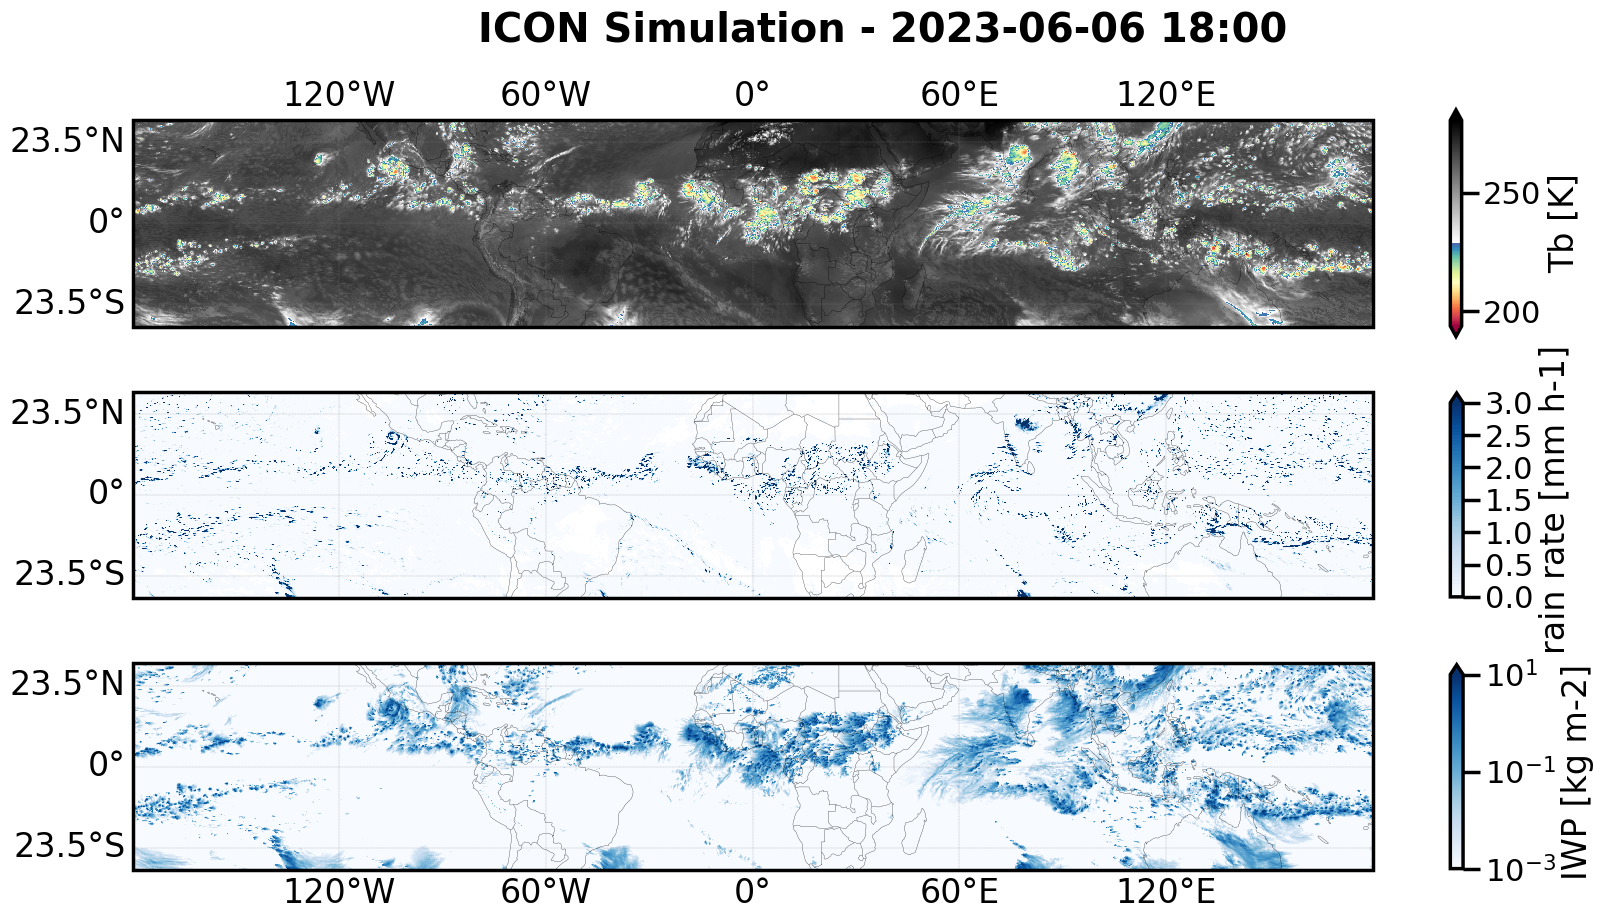

In [6]:
fig